# 03. Embeddings multimodales e índice vectorial

En la fase 3 calculamos embeddings de imagen y de texto para todo el catálogo con [Fashion-CLIP](https://huggingface.co/patrickjohncyh/fashion-clip), un modelo CLIP ajustado con alrededor de 800 mil productos de moda. Como la imagen y el texto quedan en el mismo espacio, con estos vectores podemos buscar prendas parecidas a una foto, buscar prendas a partir de una descripción o combinar las dos cosas.

Para correrlo en Kaggle hay que activar la GPU y el acceso a Internet, ya que el modelo se descarga de Hugging Face. Los inputs son la competencia de H&M, por las imágenes, y la salida del notebook 01.

Como resultado quedan `img_emb.npy` y `txt_emb.npy`, con un vector normalizado de 512 dimensiones por artículo, y `emb_ids.parquet`, que indica a qué artículo corresponde cada fila. Solo se incluyen los artículos con imagen, así que quedan fuera 442 de los 105,542.

## Configuración
Cargamos los artículos y nos quedamos con los que tienen imagen. La función `find` busca cada archivo entre los inputs del notebook, lo que permite correr el mismo código en Kaggle o en local.

In [1]:
import os, glob, time
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from transformers import CLIPModel, CLIPProcessor

KAGGLE = os.path.exists("/kaggle/input")
def find(name):
    """Busca un archivo en los Inputs del notebook (Kaggle) o en data/ (local)."""
    hits = glob.glob(f"{'/kaggle/input' if KAGGLE else 'data'}/**/{name}", recursive=True)
    assert hits, f"No encontré {name}: agrega como Input el notebook que lo genera"
    return Path(hits[0])

DATA = Path("/kaggle/input/competitions/h-and-m-personalized-fashion-recommendations")  # imágenes
OUT = Path("/kaggle/working") if KAGGLE else Path("data/03-embeddings-output")
OUT.mkdir(parents=True, exist_ok=True)

def img_path(aid):
    return DATA / "images" / aid[:3] / f"{aid}.jpg"

articles = pd.read_parquet(find("articles.parquet"))
cat = articles[articles.has_image].reset_index(drop=True)
print("Artículos con imagen:", len(cat), "/", len(articles))

Artículos con imagen: 105100 / 105542


## Modelo
Cargamos Fashion-CLIP en la GPU con media precisión para que sea más rápido. Las imágenes se rellenan con blanco hasta quedar cuadradas en lugar de recortarse, ya que las fotos de H&M son verticales y un recorte al centro podría dejar fuera parte de la prenda.

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    print("⚠️ Sin GPU: las imágenes tardarán horas. Activa GPU en Settings → Accelerator.")

MODEL = "patrickjohncyh/fashion-clip"
model = CLIPModel.from_pretrained(MODEL).to(device).eval()
if device == "cuda":
    model = model.half()
proc = CLIPProcessor.from_pretrained(MODEL)

def as_tensor(out):
    # transformers<5 devuelve un tensor; transformers>=5 un objeto cuyo pooler_output es el embedding proyectado
    return out if torch.is_tensor(out) else out.pooler_output

def prep(img):
    """Imagen PIL → tensor 3x224x224. Rellena a cuadrado con blanco en vez de recortar (no corta la prenda)."""
    img = ImageOps.pad(img.convert("RGB"), (224, 224), color="white")
    return proc.image_processor(img, return_tensors="pt")["pixel_values"][0]

@torch.no_grad()
def embed_pixels(x):
    f = as_tensor(model.get_image_features(pixel_values=x.to(device, model.dtype)))
    return torch.nn.functional.normalize(f.float(), dim=-1).cpu().numpy()

@torch.no_grad()
def embed_texts(texts, bs=512):
    out = []
    for s in range(0, len(texts), bs):
        t = proc.tokenizer(list(texts[s:s + bs]), padding=True, truncation=True,
                           max_length=77, return_tensors="pt").to(device)
        f = as_tensor(model.get_text_features(**t))
        out.append(torch.nn.functional.normalize(f.float(), dim=-1).cpu().numpy())
    return np.concatenate(out)

class Images(torch.utils.data.Dataset):
    def __init__(self, ids): self.ids = ids
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        img = Image.open(img_path(self.ids[i]))
        img.draft("RGB", (448, 448))   # decodifica el JPEG a menor resolución: mucho más rápido
        return prep(img)

config.json:   0%|          | 0.00/4.46k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/568 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## Embeddings de texto
Usamos la columna `text` que construimos en el notebook 01. CLIP solo lee los primeros 77 tokens, por eso la descripción larga puede quedar cortada, aunque la información más importante (nombre, tipo y color) va al principio. Los 105,100 textos tardan alrededor de un minuto.

In [3]:
t0 = time.time()
txt_emb = embed_texts(cat.text.tolist())
print(txt_emb.shape, f"{time.time() - t0:.0f}s")

(105100, 512) 61s


## Embeddings de imagen
Esta es la parte más pesada del notebook. Con GPU tarda unos 13 minutos para las 105,100 imágenes, así que se calcula una sola vez y se guarda.

In [4]:
t0 = time.time()
dl = torch.utils.data.DataLoader(Images(cat.article_id.tolist()), batch_size=256,
                                 num_workers=os.cpu_count() if KAGGLE else 0, pin_memory=device == "cuda")
img_emb = np.concatenate([embed_pixels(x) for x in tqdm(dl)])
print(img_emb.shape, f"{time.time() - t0:.0f}s")

  0%|          | 0/411 [00:00<?, ?it/s]

(105100, 512) 805s


Guardamos los embeddings y el orden de los artículos.

In [5]:
np.save(OUT / "img_emb.npy", img_emb)
np.save(OUT / "txt_emb.npy", txt_emb)
cat[["article_id"]].to_parquet(OUT / "emb_ids.parquet")
print(os.listdir(OUT))

['__notebook__.ipynb', 'txt_emb.npy', 'img_emb.npy', 'emb_ids.parquet']


## Índice vectorial
Como los vectores están normalizados, el producto punto entre dos de ellos es igual a su similitud coseno. Por lo tanto el índice es simplemente la matriz de embeddings, y buscar los vecinos más cercanos consiste en multiplicar y quedarse con los valores más altos. Es una búsqueda exacta, equivalente a `faiss.IndexFlatIP`.

Decidimos no usar FAISS porque con unos 105 mil vectores numpy responde una consulta en unos 20 milisegundos, y porque en macOS cargar FAISS y PyTorch en el mismo proceso provoca un error por tener dos copias de OpenMP. Un índice aproximado como FAISS IVF, HNSW o Qdrant solo vale la pena con millones de vectores.

In [6]:
def knn(Q, E, k, chunk=1024):
    """Top-k de E por producto punto para cada fila de Q → (scores, índices), ordenados de mayor a menor."""
    Q = np.atleast_2d(Q)
    S_all, I_all = [], []
    for s in range(0, len(Q), chunk):   # por bloques para no reventar la RAM
        S = Q[s:s + chunk] @ E.T
        I = np.argpartition(-S, k, axis=1)[:, :k]
        Sk = np.take_along_axis(S, I, 1)
        o = np.argsort(-Sk, axis=1)
        S_all.append(np.take_along_axis(Sk, o, 1)); I_all.append(np.take_along_axis(I, o, 1))
    return np.concatenate(S_all), np.concatenate(I_all)

t0 = time.time(); knn(img_emb[0], img_emb, 10); print(f"Una consulta sobre {len(img_emb)} artículos: {1000*(time.time()-t0):.1f} ms")

Una consulta sobre 105100 artículos: 23.1 ms


## Evaluación con los metadatos
Para 2,000 artículos al azar buscamos sus 10 vecinos más cercanos y medimos qué fracción comparte el tipo de prenda y el color. Excluimos los vecinos con el mismo `product_code`, porque son el mismo producto en otra variante y subirían la métrica de forma artificial. Como referencia calculamos también la probabilidad de acertar si se eligiera un artículo al azar.

In [7]:
ptype = cat.product_type_name.to_numpy()
colour = cat.colour_group_name.to_numpy()
pcode = cat.product_code.to_numpy()

def chance(col):
    p = pd.Series(col).value_counts(normalize=True)
    return (p ** 2).sum()

def neighbours(E, Q, q_ids, k=10):
    """Top-k vecinos de cada consulta, sin artículos del mismo producto que la consulta."""
    _, nn = knn(Q, E, k + 50)
    return np.array([[j for j in row if pcode[j] != pcode[qi]][:k] for qi, row in zip(q_ids, nn)])

def match(q_ids, nn):
    t = ptype[nn] == ptype[q_ids][:, None]
    c = colour[nn] == colour[q_ids][:, None]
    return {"tipo@10": t.mean(), "color@10": c.mean(), "tipo+color@10": (t & c).mean()}

rng = np.random.default_rng(42)
q = rng.choice(len(cat), 2000, replace=False)
eval_rows = {
    "Imagen → imagen": match(q, neighbours(img_emb, img_emb[q], q)),
    "Texto → texto": match(q, neighbours(txt_emb, txt_emb[q], q)),
    "Azar": {"tipo@10": chance(ptype), "color@10": chance(colour),
             "tipo+color@10": chance([f"{a}|{b}" for a, b in zip(ptype, colour)])},
}
pd.DataFrame(eval_rows).T.style.format("{:.3f}")

,tipo@10,color@10,tipo+color@10
Imagen → imagen,0.728,0.457,0.333
Texto → texto,0.842,0.814,0.685
Azar,0.047,0.082,0.005


## Búsqueda de texto a imagen
Esta es la búsqueda que usa el chat. Generamos consultas en inglés a partir de las 30 combinaciones de color y tipo de prenda más comunes, por ejemplo *a photo of a black trousers*, y medimos si las 10 imágenes recuperadas tienen ese tipo y ese color.

In [8]:
combos = cat.groupby(["colour_group_name", "product_type_name"]).size().nlargest(30).index.tolist()
queries = [f"a photo of a {c.lower()} {t.lower()}" for c, t in combos]
qv = embed_texts(queries)

rows = {}
for name, E in [("Texto → imagen", img_emb), ("Texto → texto del catálogo", txt_emb)]:
    _, nn = knn(qv, E, 10)
    rows[name] = {"tipo@10": np.mean([(ptype[r] == t).mean() for r, (c, t) in zip(nn, combos)]),
                  "color@10": np.mean([(colour[r] == c).mean() for r, (c, t) in zip(nn, combos)])}
eval_rows.update(rows)
pd.DataFrame(rows).T.style.format("{:.3f}")

,tipo@10,color@10
Texto → imagen,0.877,0.883
Texto → texto del catálogo,0.890,0.967


Juntamos todas las evaluaciones en una tabla. La búsqueda de texto a imagen acierta el tipo de prenda en el 88 % de los casos y el color también en el 88 %, cuando al azar ninguno pasa del 10 %. La búsqueda de imagen a imagen acierta el tipo en el 73 %, ya que dos prendas pueden verse muy parecidas aunque tengan distinta etiqueta, como un suéter y un cárdigan.

In [9]:
res = pd.DataFrame(eval_rows).T
res.to_csv(OUT / "retrieval_eval.csv")
res

,tipo@10,color@10,tipo+color@10
Imagen → imagen,0.727550,0.456500,0.333250
Texto → texto,0.842050,0.813500,0.685000
Azar,0.047351,0.082052,0.004651
Texto → imagen,0.876667,0.883333,NaN
Texto → texto del catálogo,0.890000,0.966667,NaN


## Validación visual
En cada fila la primera imagen es la consulta y las siguientes son sus 5 vecinos más cercanos de otros productos.

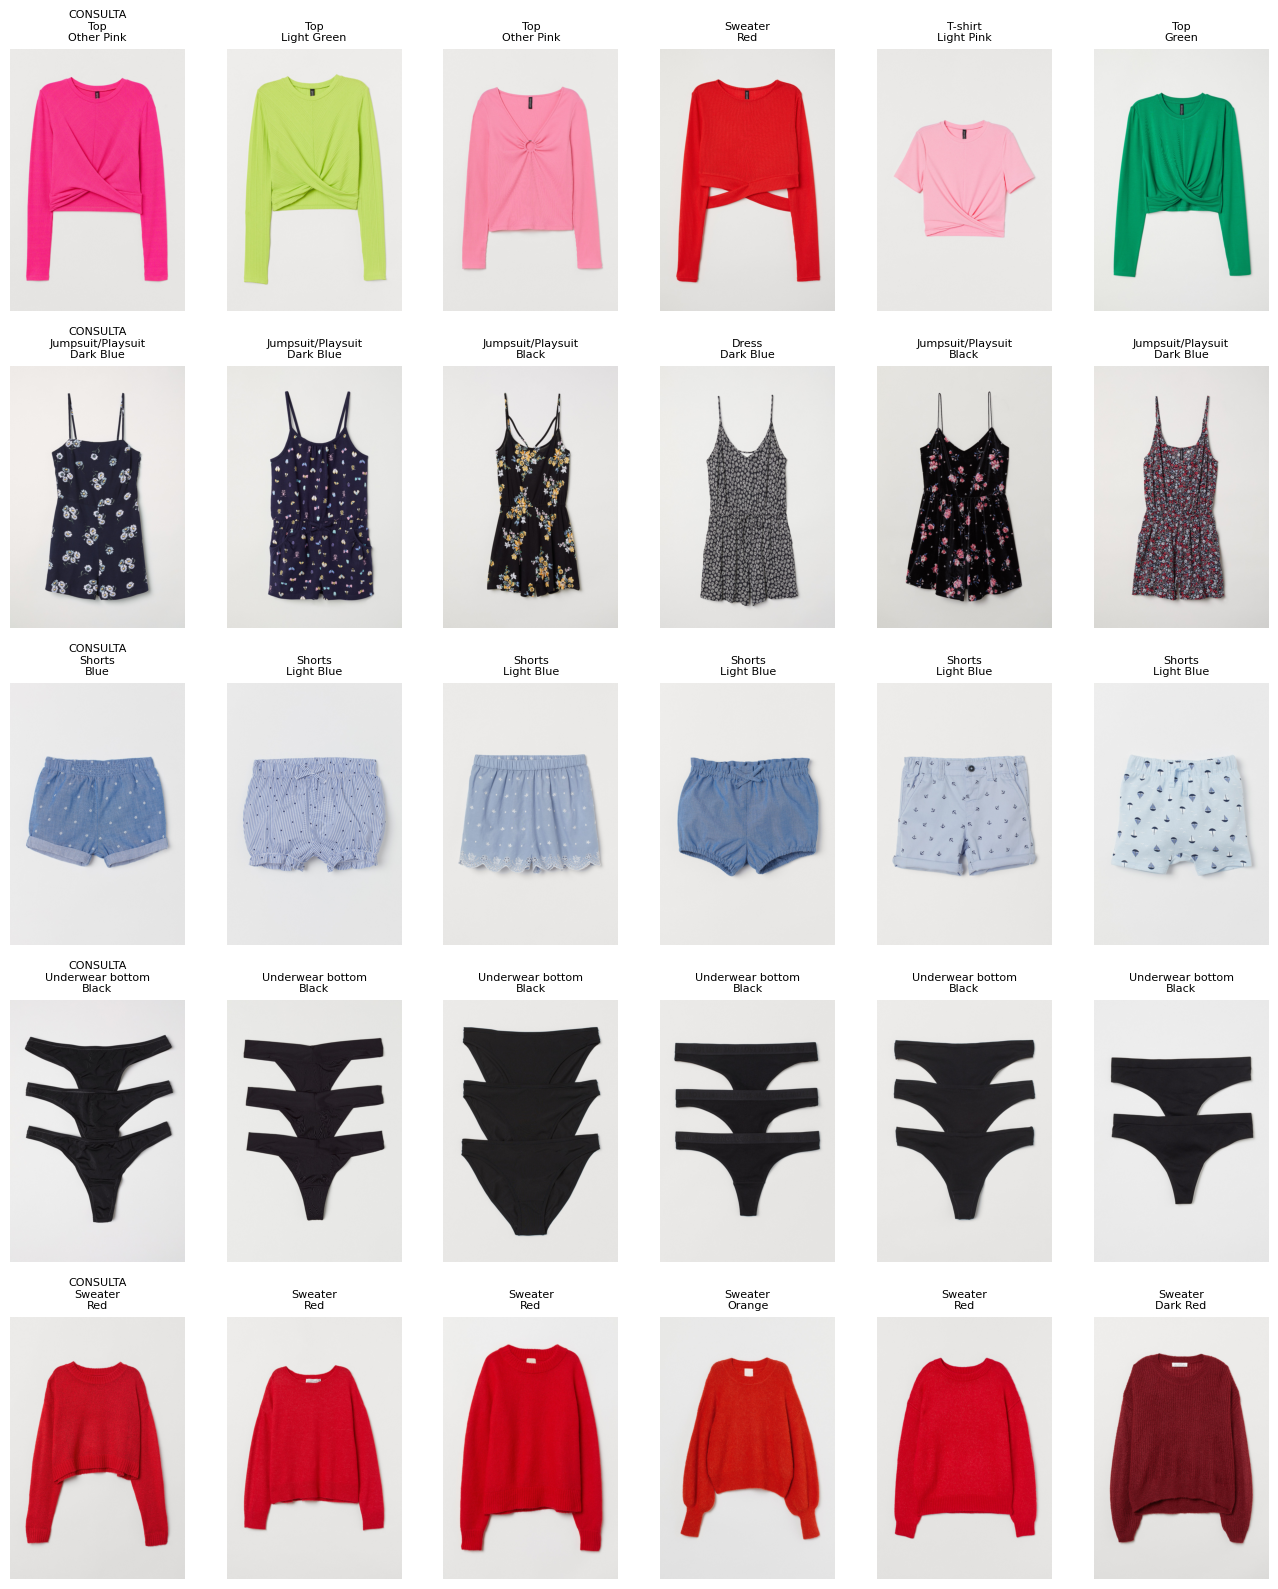

In [10]:
def show_rows(rows, titles):
    fig, axes = plt.subplots(len(rows), len(rows[0]), figsize=(2.2 * len(rows[0]), 3.2 * len(rows)))
    for ax_row, ids, ttl in zip(np.atleast_2d(axes), rows, titles):
        for ax, aid, t in zip(ax_row, ids, ttl):
            p = img_path(aid)
            ax.imshow(Image.open(p) if p.exists() else Image.new("RGB", (100, 150), "lightgray"))
            ax.set_title(t, fontsize=8); ax.axis("off")
    plt.tight_layout(); plt.show()

def label(i):
    return f"{ptype[i]}\n{colour[i]}"

qs = rng.choice(len(cat), 5, replace=False)
nn = neighbours(img_emb, img_emb[qs], qs, k=5)
show_rows([[cat.article_id[i] for i in [qi, *r]] for qi, r in zip(qs, nn)],
          [[("CONSULTA\n" if j == 0 else "") + label(i) for j, i in enumerate([qi, *r])] for qi, r in zip(qs, nn)])

Hacemos lo mismo con consultas de texto. Así podemos revisar a simple vista si la búsqueda tiene sentido.

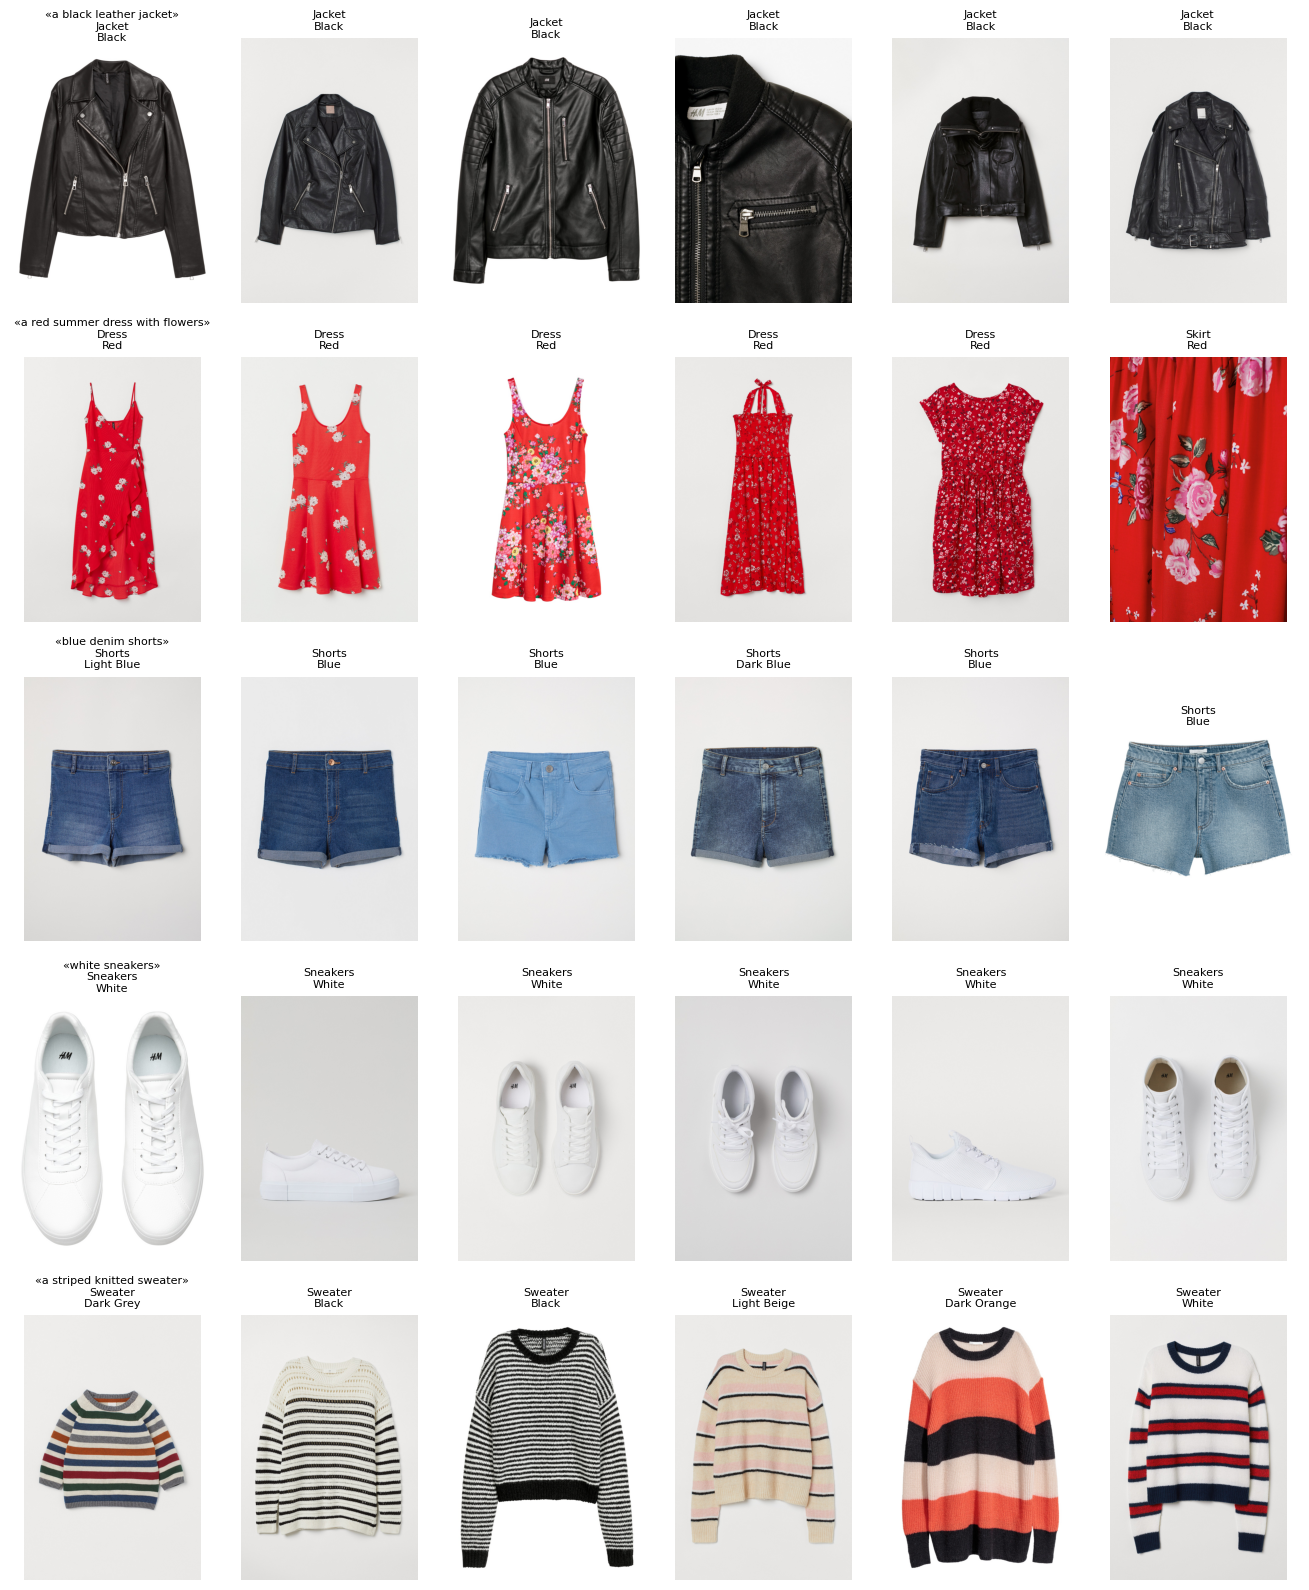

In [11]:
demo = ["a black leather jacket", "a red summer dress with flowers", "blue denim shorts",
        "white sneakers", "a striped knitted sweater"]
_, nn = knn(embed_texts(demo), img_emb, 6)
show_rows([[cat.article_id[i] for i in r] for r in nn],
          [[(f"«{d}»\n" if j == 0 else "") + label(i) for j, i in enumerate(r)] for d, r in zip(demo, nn)])